Published on September 06, 2026. By Marília Prata, mpwolke.

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.graph_objs as go
import plotly.offline as py
import plotly.express as px

#Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

ModuleNotFoundError: No module named 'kagglehub'

![](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQmmtocU4d_nDjKZVjlHbc5AJIuOAgQCQ5SFaO0dyIPiw&s=10)

## Competition Citation

@misc{nfl-big-data-bowl-2027,

    author = {Michael Lopez and Ally Blake, and Tom Bliss and Addison Howard and Paul Mooney},
    title = {NFL Big Data Bowl 2027},
    
    year = {2026},
    howpublished = {\url{https://www.kaggle.com/competitions/nfl-big-data-bowl-2027}},
    note = {Kaggle}
}

## Load (some of the) files

In [ ]:
player_play = pd.read_csv("../input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/player_play.csv")
games = pd.read_csv("../input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/games.csv")
career = pd.read_csv("../input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/player_career_successes.csv")
players = pd.read_csv("../input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/players.csv")
results = pd.read_csv("../input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/combine_results.csv")
tracking = pd.read_csv("../input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/combine_tracking.csv")

### NFL players

In [ ]:
players.head()

,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick
0,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1.0,3.0,3.0
1,55870,Paris Johnson,2023,T,2001-07-31,Ohio State,Big Ten Conference,1.0,6.0,6.0
2,55874,Darnell Wright,2023,T,2001-08-10,Tennessee,Southeastern Conference,1.0,10.0,10.0
3,55875,Peter Skoronski,2023,G,2001-07-31,Northwestern,Big Ten Conference,1.0,11.0,11.0
4,55877,Lukas Van Ness,2023,DE,2001-07-06,Iowa,Big Ten Conference,1.0,13.0,13.0


### If any data doesn't match format "%Y-%m-%d". Use format='mixed'

On the snippet below, 2nd line https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.to_datetime.html

In [ ]:
#https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.to_datetime.html

print("Data type of birthDate column before parsing : ", players["birth_date"].dtypes)
players["birth_date"] = pd.to_datetime(players["birth_date"], format='mixed')
print("Data type of birth_date column after parsing : ", players["birth_date"].dtypes)
print(players["birth_date"].head())

Data type of birthDate column before parsing :  object
Data type of birth_date column after parsing :  datetime64[ns]
0   2001-09-02
1   2001-07-31
2   2001-08-10
3   2001-07-31
4   2001-07-06
Name: birth_date, dtype: datetime64[ns]


### Splitting YYYY (Year) from YYYY-MM-DD date format

In [ ]:
players['birthYear'] = pd.DatetimeIndex(players['birth_date']).year
print(players["birthYear"])

0      2001
1      2001
2      2001
3      2001
4      2001
       ... 
505    2001
506    2002
507    2000
508    2002
509    2001
Name: birthYear, Length: 510, dtype: int32


### Unique values of birthYear column

In [ ]:
print("Unique birth year values and their counts :")
print(players["birthYear"].value_counts())

Unique birth year values and their counts :
birthYear
2001    154
2000    123
2002    101
1999     60
2003     48
2004     13
1998     10
1997      1
Name: count, dtype: int64


### Youngest and Oldest Player birth year

In [ ]:
#Sanjay V https://www.kaggle.com/code/sanjayv007/nfl-big-data-bowl-beginner-s-complete-eda

# Newest and oldest player
print("Youngest player birth year : ",max(players["birthYear"]))
print("Oldest player birth year : ",min(players["birthYear"]))

Youngest player birth year :  2004
Oldest player birth year :  1997


### The higher bars are the represented by 2000/2001/2002 years. More players were born on these years.

It's a normal distribution.

https://www.labxchange.org/library/items/lb:LabXchange:10d3270e:html:1

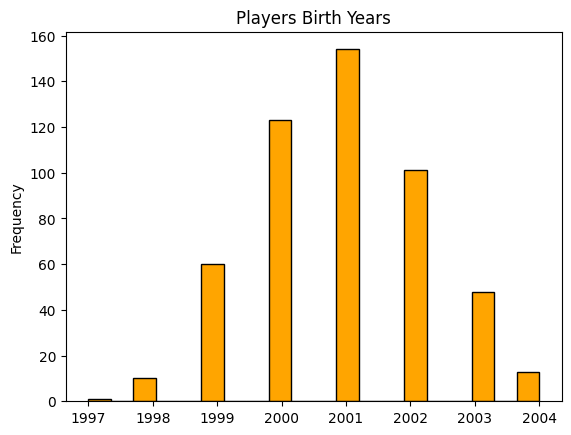

In [ ]:
hist = players["birthYear"].plot.hist(bins=20, color="orange", edgecolor="black")
plt.title('Players Birth Years');

### Unique values of collegeName column

In [ ]:
print("Unique college names and their counts : ")
college_names = players.pivot_table(index = ['college_name'], aggfunc = 'size') 
college_names = college_names.reset_index()
college_names.columns= ["College Names", "Counts"]
college_names = college_names.sort_values("Counts", ascending = False)
print(college_names)

Unique college names and their counts : 
            College Names  Counts
30                Georgia      22
0                 Alabama      16
45        Louisiana State      15
67             Ohio State      14
81         South Carolina      14
..                    ...     ...
87   Southern Mississippi       1
101            Utah State       1
97                   Troy       1
108      Western Kentucky       1
111               Wyoming       1

[112 rows x 2 columns]


### Top 10 colleges having higher number of players

In [ ]:
top_colleges = college_names[0:10]
print(top_colleges)

      College Names  Counts
30          Georgia      22
0           Alabama      16
45  Louisiana State      15
67       Ohio State      14
81   South Carolina      14
91            Texas      14
51         Michigan      12
5          Arkansas      11
48         Maryland      11
50            Miami      11


### Attempt number index for the prospect within the given drill.

"In the NFL, a drill refers to a specialized, repetitive training or evaluation exercise used to teach, refine, or test specific football skills—such as speed, agility, tackling technique, or play execution—rather than a full team scrimmage."

In [ ]:
print("Unique NFL Attempts and their counts :")
g_attempt = tracking.pivot_table(index = ['attempt'], aggfunc = 'size') 
g_attempt = g_attempt.reset_index()
g_attempt.columns= ["Attempt", "Counts"]
g_attempt = g_attempt.sort_values("Counts", ascending = False)
print(g_attempt)

Unique NFL Attempts and their counts :
    Attempt  Counts
0         1  247474
1         2   75934
2         3   23012
6         7   14697
5         6   14237
4         5   14046
3         4   13486
7         8   12616
9        10   11056
8         9   10527
10       11    8639
11       12    6335
12       13    4980
13       14    3572
14       15    1836
15       16     668
16       17      74


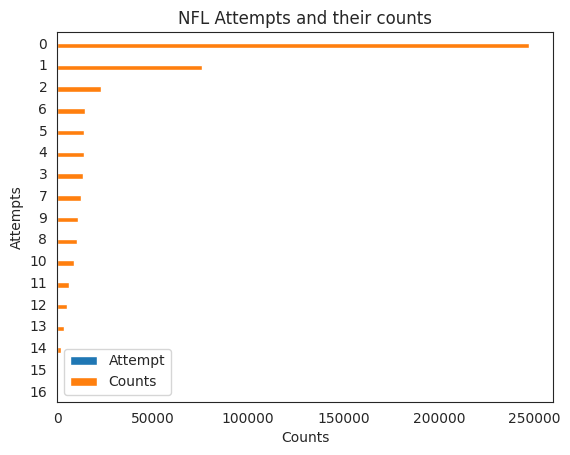

In [ ]:
# Add titles, labels, invert y-axis

bar_plot = g_attempt.plot.barh()
bar_plot.set_title("NFL Attempts and their counts")
bar_plot.set_xlabel("Counts")
bar_plot.set_ylabel("Attempts")
bar_plot.invert_yaxis()
plt.show(bar_plot)

### Highest height in feet

In [ ]:
height = results[results['combine_height'] == max(results["combine_height"])]
height

,draft_year,nfl_id,combine_position,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score
309,2024,57126,OL,80.625,321,10.0,34.25,82.75,1.73,5.05,28.0,112.0,7.31,4.51,27.0,88,87.0,93.0


## Lowest height in feet

In [ ]:
low_height = results[results['combine_height'] == min(results["combine_height"])]
low_height

,draft_year,nfl_id,combine_position,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score
396,2025,58413,WR,68.125,174,8.75,30.375,74.5,1.54,4.46,38.0,128.0,NaN,4.41,NaN,62,55.0,55.0


### Colleges with a higher number of Players

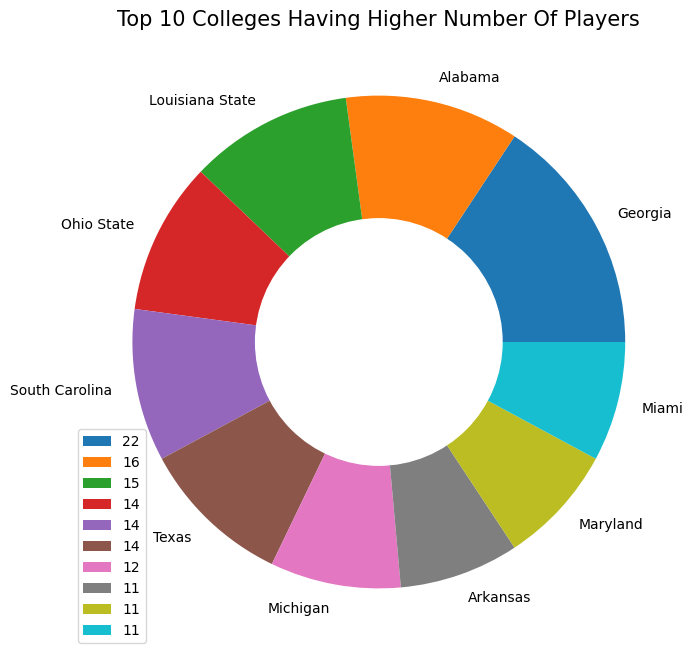

In [ ]:
# Creating Donut Plot
fig = plt.figure(figsize = (8, 8)) 
circle = plt.Circle( (0,0), 0.5, color = 'white')
plt.pie(top_colleges["Counts"], labels = top_colleges["College Names"])
p = plt.gcf()
p.gca().add_artist(circle)
#plt.legend(loc=(1.04, 1))
plt.legend(top_colleges["Counts"])
plt.title("Top 10 Colleges Having Higher Number Of Players", fontsize=15)

# Displaying Donut Plot
plt.show() 

### Unique values of NFL Position column

**Offense**

• QB (Quarterback): Directs the offense, calls plays, and passes, hands off, or runs with the ball.

• RB (Running Back / Halfback): Runs with the ball, catches passes, and blocks.

• FB (Fullback): Acts primarily as a lead blocker and occasional short-yardage rusher.

• WR (Wide Receiver): Lines up near the sidelines to run pass routes and catch the ball.

• TE (Tight End): A hybrid player who blocks like a lineman or catches passes like a receiver.

• C (Center): Lines up in the middle of the offensive line and "snaps" the ball to the QB.

• G (Guard / LG, RG): Lines up on either side of the center to block defenders.

• T (Tackle / LT, RT): Lines up on the outer ends of the offensive line to protect against edge rushers

**Defense**

• DT (Defensive Tackle): Lines up in the interior defensive line to stop the run and pressure the pocket.

• NT (Nose Tackle): A massive interior defensive lineman positioned directly over the center.

• DE (Defensive End): Lines up on the outside of the defensive line to contain runs and rush the passer.

• EDGE (Edge Rusher): Modern roster/position term combining 4-3 DEs and 3-4 OLBs who rush the passer.

• ILB / MLB (Inside / Middle Linebacker): Plays behind the defensive line, calls defensive adjustments, and stops the run.

• OLB (Outside Linebacker): Operates on the outer edges to defend the run, cover tight ends/backs, or blitz.

• CB (Cornerback): Covers wide receivers in the secondary to break up passes or intercept the ball.

• SS (Strong Safety): Lines up closer to the box/line to support run defense and short-to-intermediate coverage.

• FS (Free Safety): Plays deeper in the secondary as the last line of defense against long passes.

• DB (Defensive Back): General umbrella term for cornerbacks and safeties

**Special Teams**

• K (Kicker / Placekicker): Handles field goals, extra points, and kickoffs.

• P (Punter): Kicks the ball away to the opponent on fourth down.

• LS (Long Snapper): Specialized center who snaps the ball long-distance to the punter or holder.

• KR (Kick Returner): Receives the ball on kickoffs and runs it back.

• PR (Punt Returner): Receives the ball on punts and runs it back

https://www.marca.com/en/nfl/2022/01/08/61d9d3c422601d7f648b45a5.html

In [ ]:
print("Unique position values and their counts :")
pos_val = players.pivot_table(index = ['nfl_position'], aggfunc = 'size') 
pos_val = pos_val.reset_index()
pos_val.columns= ["Positions", "Counts"]
pos_val = pos_val.sort_values("Counts", ascending = False)
print(pos_val)

Unique position values and their counts :
   Positions  Counts
16        WR     106
1         CB      60
7          G      51
14         T      50
4         DT      47
15        TE      42
3         DE      36
11       OLB      30
13        SS      28
6         FS      25
0          C      20
2         DB       5
10        NT       5
8        ILB       2
5         FB       1
12        RB       1
9        MLB       1


### Oldest and youngest players

In [ ]:
oldest = players[players['birthYear'] == min(players["birthYear"])]
oldest

,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick,birthYear
285,57355,Devaughn Vele,2024,WR,1997-12-12,Utah,Pacific Twelve Conference,7.0,15.0,235.0,1997


In [ ]:
youngest = players[players['birthYear'] == max(players["birthYear"])]
youngest

,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick,birthYear
337,58206,Will Campbell,2025,T,2004-01-06,Louisiana State,Southeastern Conference,1.0,4.0,4.0,2004
338,58209,Armand Membou,2025,T,2004-03-27,Missouri,Southeastern Conference,1.0,7.0,7.0,2004
339,58211,Kelvin Banks,2025,T,2004-03-10,Texas,Southeastern Conference,1.0,9.0,9.0,2004
340,58214,Tyler Booker,2025,G,2004-04-12,Alabama,Southeastern Conference,1.0,12.0,12.0,2004
348,58242,Jonah Savaiinaea,2025,G,2004-01-13,Arizona,Big Twelve Conference,2.0,5.0,37.0,2004
350,58247,Mason Taylor,2025,TE,2004-05-08,Louisiana State,Southeastern Conference,2.0,10.0,42.0,2004
355,58256,Nic Scourton,2025,OLB,2004-08-25,Texas A&M,Southeastern Conference,2.0,19.0,51.0,2004
364,58272,Harold Fannin,2025,TE,2004-07-20,Bowling Green,Mid-American Conference,3.0,3.0,67.0,2004
369,58278,Azareye'h Thomas,2025,CB,2004-07-06,Florida State,Atlantic Coast Conference,3.0,9.0,73.0,2004
378,58296,Emery Jones,2025,G,2004-03-05,Louisiana State,Southeastern Conference,3.0,27.0,91.0,2004


In [ ]:
mean=np.ceil(players['draft_pick_within_round'].mean())
median=np.ceil(players['draft_pick_within_round'].median())

## draft_pick_within_round

"In sports data tracking and fantasy software (such as nflreadr), draft_pick_within_round represents the exact numerical position a player was selected specifically within a single round, rather than their overall position in the entire draft."

**Metric**	    

draft_round	Definition:The specific round of the draft.	Ex: Round 2	

draft_pick (within round)Definition:The pick number inside just that round. Ex:Pick 2	

draft_ovr	Definition:The sequential pick number from the very start of the draft.	Ex:Pick 34

https://cran.r-project.org/web/packages/nflreadr/vignettes/dictionary_ff_playerids.html

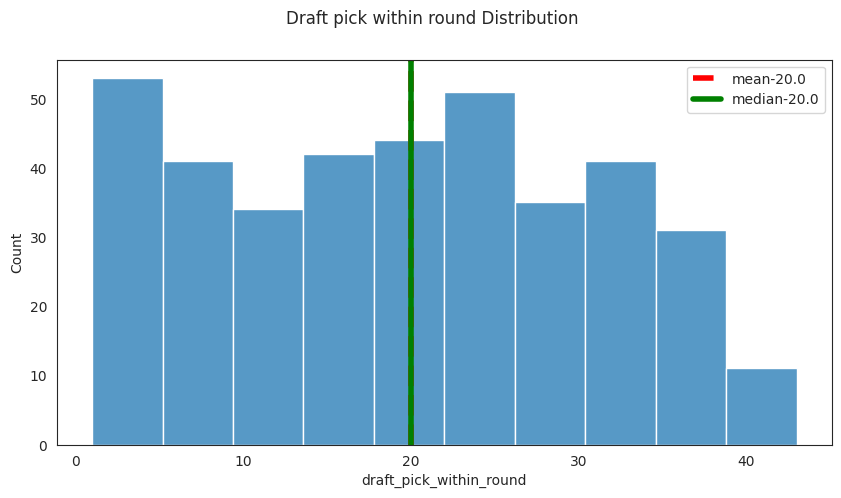

In [ ]:
#Code by Chinta https://www.kaggle.com/chinta/mlb-is-player-age-important

plt.figure(figsize=(10, 5))
sns.set_style('white')
hist_plot = sns.histplot(players['draft_pick_within_round'], )
hist_plot.axvline(mean, color='r', linestyle='--', linewidth = 4, label = f'mean-{mean}')
hist_plot.axvline(median, color='g', linestyle='-', linewidth = 4, label = f'median-{median}')
plt.suptitle("Draft pick within round Distribution")
plt.legend();

## Games file

In [ ]:
games.tail(3)

,game_id,game_key,season,season_type,week,home_team_abbr,visitor_team_abbr
999,2026012500,60174,2025,POST,21,DEN,NE
1000,2026012501,60175,2025,POST,21,SEA,LAR
1001,2026020800,60176,2025,POST,23,NE,SEA


### Unique values of season column

In [ ]:
#By Sanjay V https://www.kaggle.com/code/sanjayv007/nfl-big-data-bowl-beginner-s-complete-eda

print("Unique NFL seasons and their counts :")
g_season = games.pivot_table(index = ['season'], aggfunc = 'size') 
g_season = g_season.reset_index()
g_season.columns= ["Seasons", "Counts"]
g_season = g_season.sort_values("Counts", ascending = False)
print(g_season)

Unique NFL seasons and their counts :
   Seasons  Counts
0     2023     334
1     2024     334
2     2025     334


### NFL weeks

In [ ]:
#By Sanjay V https://www.kaggle.com/code/sanjayv007/nfl-big-data-bowl-beginner-s-complete-eda

print("Unique NFL weeks and their counts :")
g_week = games.pivot_table(index = ['week'], aggfunc = 'size') 
g_week = g_week.reset_index()
g_week.columns= ["Weeks", "Counts"]
g_week = g_week.sort_values("Counts", ascending = False)
print(g_week)

Unique NFL weeks and their counts :
    Weeks  Counts
1       1      96
2       2      96
3       3      96
4       4      48
16     16      48
17     17      48
18     18      48
15     15      48
8       8      45
13     13      45
6       6      44
11     11      43
12     12      43
9       9      43
7       7      43
14     14      42
5       5      42
10     10      42
19     19      18
20     20      12
21     21       6
0       0       3
22     23       3


### Unique NFL weeks

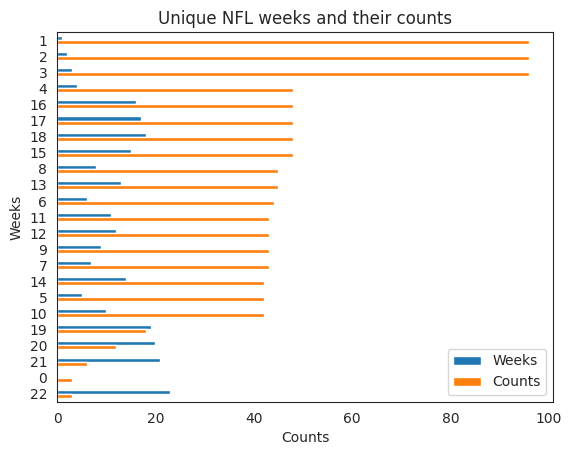

In [ ]:
# Add titles, labels, invert y-axis

bar_plot = g_week.plot.barh()
bar_plot.set_title("Unique NFL weeks and their counts")
bar_plot.set_xlabel("Counts")
bar_plot.set_ylabel("Weeks")
bar_plot.invert_yaxis()
plt.show(bar_plot)

### Unique values from home_team_abbr column

In [ ]:
#By Sanjay V https://www.kaggle.com/code/sanjayv007/nfl-big-data-bowl-beginner-s-complete-eda

print("Unique NFL home teams and their counts :")
g_home = games.pivot_table(index = ['home_team_abbr'], aggfunc = 'size') 
g_home = g_home.reset_index()
g_home.columns= ["Home Team", "Counts"]
g_home = g_home.sort_values("Counts", ascending = False)
print(g_home)

Unique NFL home teams and their counts :
   Home Team  Counts
26       PHI      35
15        KC      34
3        BUF      34
10       DET      34
5        CHI      33
22        NE      33
2        BAL      33
30        TB      32
12       HOU      32
9        DEN      32
28       SEA      32
29        SF      32
27       PIT      31
14       JAX      31
8        DAL      31
7        CLE      31
4        CAR      31
0        ARI      30
19        LV      30
11        GB      30
6        CIN      30
1        ATL      30
13       IND      30
20       MIA      30
17       LAC      30
31       TEN      30
24       NYG      30
21       MIN      30
23        NO      30
32       WAS      30
25       NYJ      30
16        LA      21
18       LAR      10


Since the teams have almost the same number of entries, any chart won't bring information, except the name of the teams by itself.

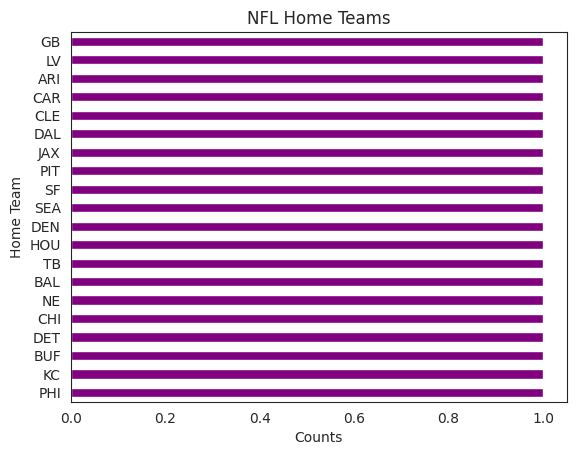

In [ ]:
#Code by Lucas Abrahão https://www.kaggle.com/lucasabrahao/trabalho-manufatura-an-lise-de-dados-no-brasil

g_home["Home Team"].value_counts().head(20).plot.barh(color='purple', title='NFL Home Teams')
plt.xlabel('Counts');

### Unique values from yards_to_go column

In [ ]:
#By Sanjay V https://www.kaggle.com/code/sanjayv007/nfl-big-data-bowl-beginner-s-complete-eda

print("Unique NFL yards to go and their counts :")
g_yards = player_play.pivot_table(index = ['yards_to_go'], aggfunc = 'size') 
g_yards = g_yards.reset_index()
g_yards.columns= ["Yards To Go", "Counts"]
g_yards = g_yards.sort_values("Counts", ascending = False)
print(g_yards)

Unique NFL yards to go and their counts :
    Yards To Go  Counts
10           10  145764
6             6   16415
5             5   16216
7             7   15711
1             1   15664
8             8   14886
4             4   14262
3             3   12830
9             9   12812
2             2   11450
11           11    6583
15           15    6100
12           12    4761
20           20    3616
13           13    3579
14           14    3048
16           16    2098
17           17    1786
18           18    1691
19           19    1220
0             0     961
21           21     601
25           25     430
22           22     429
23           23     346
24           24     239
26           26     190
30           30     102
27           27     100
28           28      91
29           29      77
31           31      40
34           34      38
33           33      23
32           32      13
36           36      10
39           40       7
35           35       3
38           38       

### Yards to go

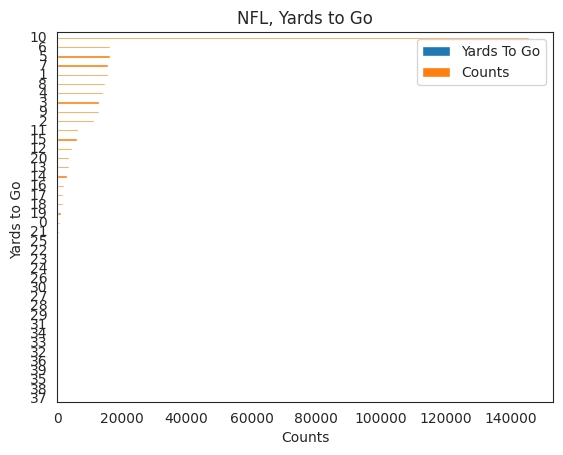

In [ ]:
# Add titles, labels, invert y-axis

bar_plot = g_yards.plot.barh()
bar_plot.set_title("NFL, Yards to Go")
bar_plot.set_xlabel("Counts")
bar_plot.set_ylabel("Yards to Go ")
bar_plot.invert_yaxis() #order increasing
plt.show(bar_plot)

### Unique values from offense_formation column - NFL Offense Formation

**EMPTY backfield**

"Also known simply as "Five-wide", a reference to the five wide receivers. In the empty backfield formation, all of the backs play near the line of scrimmage to act as extra wide receivers or tight ends, with the quarterback lining up either under center or, most commonly, in the shotgun. This is almost exclusively a passing formation used to spread the field, often to open up short inside routes or screen routes. The most common running play from this formation is a quarterback draw play up the middle since defensive players are spread out from sideline to sideline."

**PISTOL**

"It is essentially a shotgun variation, with the quarterback lined up closer than in standard shotgun (normally 3 to 4 yards behind center), and a running back lined up behind, rather than next to, the QB (normally at 3 to 4 yards behind quarterback). The pistol formation adds the dimension of a running game with the halfback being in a singleback position. This has disrupted the timing of some defenses with the way the quarterback hands the ball off to the halfback. This also allows the smaller halfbacks to hide behind the offensive line, causing opposing linebackers and pass-rushing defensive linemen to play more conservatively."

**JUMBO**

"Goal line formation. Also called "jumbo", "heavy", "full house" and other similar names, this formation is used exclusively in short-yardage situations, and especially near the goal line. This formation typically has no wide receivers, and often employs 3 tight ends and 2 running backs, or alternately 2 tight ends and 3 running backs. Often, a tight end or full back position is occupied by a player who normally plays offensive line or defensive line positions to act as an extra blocker."

**WILDCAT**

"The wildcat is primarily a running formation in which an athletic player (usually a running back or a receiver who runs well) takes the place of the team's usual quarterback in a shotgun formation while the quarterback lines up wide as a flanker or is replaced by another player. The ball is snapped to the runner, who usually has the option of either running the ball himself or handing it to another running back lined up in the backfield. The wildcat gives the runner a good look at the defense before the snap, allowing him to choose the best running lane. It also allows for ten offensive players to block, unlike in a conventional running play, in which the quarterback is usually not involved after delivering the ball to a running back."

https://en.wikipedia.org/wiki/List_of_formations_in_American_football

In [ ]:
#By Sanjay V https://www.kaggle.com/code/sanjayv007/nfl-big-data-bowl-beginner-s-complete-eda

print("Unique NFL Offense Formation and their counts :")
gp_type = player_play.pivot_table(index = ['offense_formation'], aggfunc = 'size') 
gp_type = gp_type.reset_index()
gp_type.columns= ["Offense Formation", "Counts"]
gp_type = gp_type.sort_values("Counts", ascending = False)
print(gp_type)

Unique NFL Offense Formation and their counts :
  Offense Formation  Counts
4           SHOTGUN  182052
5        SINGLEBACK   69220
0             EMPTY   22754
1            I_FORM   16406
3            PISTOL   14880
2             JUMBO    2708
6           WILDCAT     842


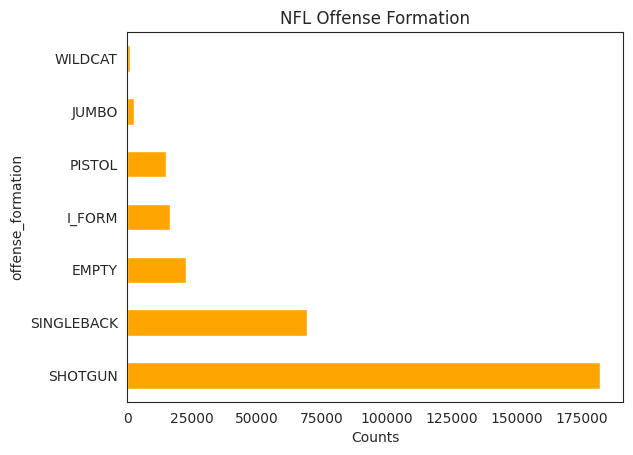

In [ ]:
#Code by Lucas Abrahão https://www.kaggle.com/lucasabrahao/trabalho-manufatura-an-lise-de-dados-no-brasil

player_play["offense_formation"].value_counts().plot.barh(color='orange', title='NFL Offense Formation')
plt.xlabel('Counts');

## Target

In [ ]:
#By Sanjay V https://www.kaggle.com/code/sanjayv007/nfl-big-data-bowl-beginner-s-complete-eda

print("Unique NFL Target and their counts :")
g_home = player_play.pivot_table(index = ['target'], aggfunc = 'size') 
g_home = g_home.reset_index()
g_home.columns= ["Target", "Counts"]
g_home = g_home.sort_values("Counts", ascending = False)
print(g_home)

Unique NFL Target and their counts :
   Target  Counts
0   False  304355
1    True    9842


Target Distribution:
    0  |  304,355  (96.87%)  ████████████████████████████████████████████████
    1  |   9,842  (3.13%)  █


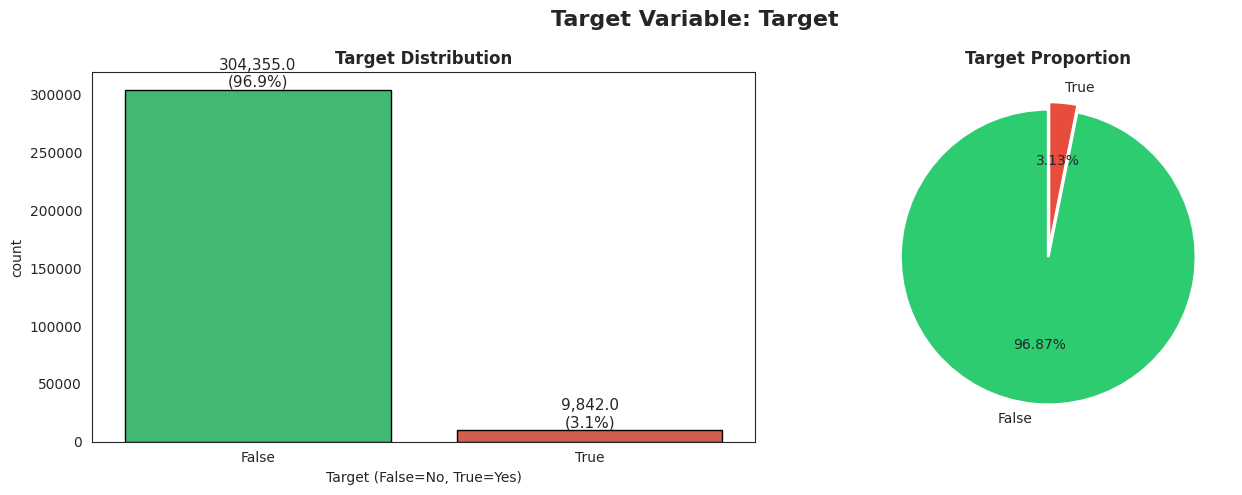

In [ ]:
#By Yusufu Murtaza https://www.kaggle.com/code/yusufmurtaza01/s6e3-eda-training

target_counts = player_play['target'].value_counts()
target_pcts   = player_play['target'].value_counts(normalize=True) * 100

print("Target Distribution:")
for val, cnt, pct in zip(target_counts.index, target_counts, target_pcts):
    bar = "█" * int(pct / 2)
    print(f"  {val:>3}  |  {cnt:>6,}  ({pct:.2f}%)  {bar}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Count plot
sns.countplot(x='target', data=player_play, ax=axes[0],
              palette=['#2ECC71', '#E74C3C'], edgecolor='black')
axes[0].set_title('Target Distribution', fontweight='bold')
axes[0].set_xlabel('Target (False=No, True=Yes)')
for p in axes[0].patches:
    axes[0].annotate(
        f'{p.get_height():,}\n({p.get_height()/len(player_play)*100:.1f}%)',
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha='center', va='bottom', fontsize=11)

# Pie chart
axes[1].pie(target_counts, labels=['False', 'True'],
            autopct='%1.2f%%', startangle=90,
            colors=['#2ECC71', '#E74C3C'], explode=(0, 0.05),
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Target Proportion', fontweight='bold')

plt.suptitle('Target Variable: Target', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('/kaggle/working/eda_01_target.png', dpi=120, bbox_inches='tight')
plt.show()

## Unique values of pass result column

Pass Result: C, I, S, R, IN

Dropback outcome of the play (C: Complete pass, I: Incomplete pass, S: Quarterback sack, IN: Intercepted pass, R: Scramble, text)

In [ ]:
#By Sanjay V https://www.kaggle.com/code/sanjayv007/nfl-big-data-bowl-beginner-s-complete-eda

print("Unique NFL pass results and their counts :")
g_res = player_play.pivot_table(index = ['pass_result'], aggfunc = 'size') 
g_res = g_res.reset_index()
g_res.columns= ["Pass Results", "Counts"]
g_res = g_res.sort_values("Counts", ascending = False)
print(g_res)

Unique NFL pass results and their counts :
  Pass Results  Counts
0            C  115903
1            I   65187
4            S   13888
3            R   11326
2           IN    4257


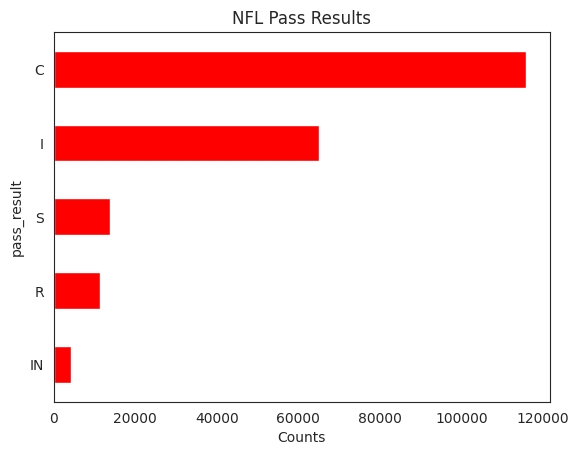

In [ ]:
#Code by Lucas Abrahão https://www.kaggle.com/lucasabrahao/trabalho-manufatura-an-lise-de-dados-no-brasil

#sort_values() to rank increasing values

player_play["pass_result"].value_counts().sort_values().plot.barh(color='red', title='NFL Pass Results')
plt.xlabel('Counts');

## Game Tracking 2025

In [ ]:
tracking25 = pd.read_csv("../input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027/game_tracking_2025.csv")
tracking25.head()

,game_id,play_id,nfl_id,time,x,y,s,a,dis,o,dir,event
0,2025090701,290,57347,2025-09-07T17:09:39.500,83.06,32.06,0.10,0.06,0.04,8.00,18.86,NaN
1,2025090701,290,57347,2025-09-07T17:09:39.600,83.07,32.07,0.10,0.07,0.02,2.61,21.95,NaN
2,2025090701,290,57347,2025-09-07T17:09:39.700,83.06,32.06,0.07,0.05,0.02,357.42,16.24,NaN
3,2025090701,290,57347,2025-09-07T17:09:39.800,83.07,32.07,0.07,0.05,0.01,352.73,18.93,NaN
4,2025090701,290,57347,2025-09-07T17:09:39.900,83.08,32.07,0.06,0.05,0.01,349.52,20.80,NaN


## Splitting date from datetime

In [ ]:
#By Sanjay V https://www.kaggle.com/code/sanjayv007/nfl-big-data-bowl-beginner-s-complete-eda

tracking25['date'] = pd.DatetimeIndex(tracking25['time']).date
print(tracking25["date"])

0           2025-09-07
1           2025-09-07
2           2025-09-07
3           2025-09-07
4           2025-09-07
               ...    
11160898    2025-10-21
11160899    2025-10-21
11160900    2025-10-21
11160901    2025-10-21
11160902    2025-10-21
Name: date, Length: 11160903, dtype: object


### Unique values from date column

In [ ]:
#By Sanjay V https://www.kaggle.com/code/sanjayv007/nfl-big-data-bowl-beginner-s-complete-eda

print("Unique NFL dates and their counts :")
tr_date = tracking25.pivot_table(index = ['date'], aggfunc = 'size') 
tr_date = tr_date.reset_index()
tr_date.columns= ["Date", "Counts"]
tr_date = tr_date.sort_values("Counts", ascending = False)
print(tr_date)

Unique NFL dates and their counts :
          Date  Counts
88  2026-01-04  457463
24  2025-09-21  428230
20  2025-09-14  416390
56  2025-11-16  404329
73  2025-12-14  403750
..         ...     ...
77  2025-12-20   17245
94  2026-01-17   17051
0   2025-08-01   16658
5   2025-08-15   13827
99  2026-02-08    5453

[101 rows x 2 columns]


### x_ticks Rotation=0

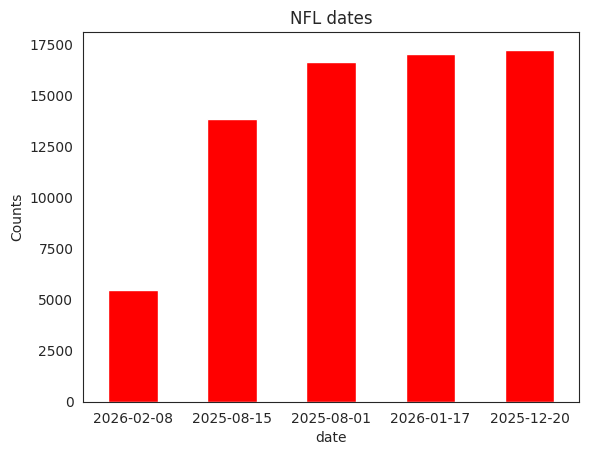

In [ ]:
#Code by Lucas Abrahão https://www.kaggle.com/lucasabrahao/trabalho-manufatura-an-lise-de-dados-no-brasil

#sort_values() to rank increasing values

tracking25["date"].value_counts().sort_values().head().plot.bar(color='red', title='NFL dates')
plt.xticks(rotation=0)
plt.ylabel('Counts');

## Creating new dataset using play_id, event and game_id

Players positions

x: Player position along the long axis of the field, 0 - 120 yards. See Figure 1 below. (numeric)

y: Player position along the short axis of the field, 0 - 53.3 yards. See Figure 1 below. (numeric

event: Team abbrevation of corresponding player (text)

https://www.kaggle.com/competitions/nfl-big-data-bowl-2025/data?select=tracking_week_1.csv)

In [ ]:
data = tracking25.query('play_id == 290 and game_id == 2025090701')
print(data[["x", "y", "event"]])

             x      y event
0        83.06  32.06   NaN
1        83.07  32.07   NaN
2        83.06  32.06   NaN
3        83.07  32.07   NaN
4        83.08  32.07   NaN
...        ...    ...   ...
5617410  84.00  28.25   NaN
5617411  83.94  28.15   NaN
5617412  83.89  28.06   NaN
5617413  83.83  27.96   NaN
5617414  83.77  27.86   NaN

[440 rows x 3 columns]


### Players Events

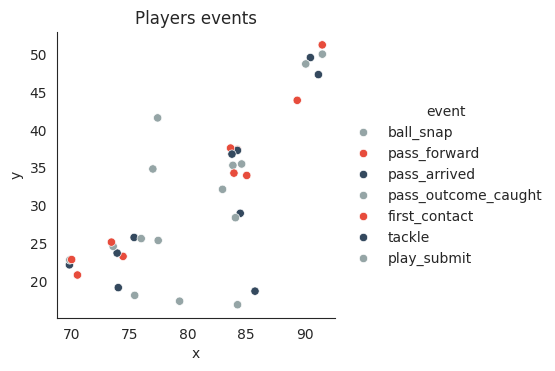

In [ ]:
#By Rob Mulla

# define a custom palette
my_palette = ["#95a5a6", "#e74c3c", "#34495e"]
sns.pairplot(
    data,
    x_vars=["x"],
    y_vars=["y"],
    height=3.5,
    hue="event", #hue define the color-code variable
    palette=my_palette,   # <-- see here, custom palette
)
plt.title('Players events')
plt.show()

In [ ]:
#By Lennart Haupts https://www.kaggle.com/code/lennarthaupts/getting-a-feel-for-the-tracking-data

# only looking at data from plays when the home team is on the offense
right = player_play[player_play['play_direction'] == 'right']
# only looking at a specific match
match = right[right['game_id'] == 2025111610]

## Heatmap of Pre Snap Home Score/Expected Points during a tackle when the offense is moving to the right 

### Really NFL? 🤣

Probably, that doesn't exist or anybody has ever heard about that in NFL : )

That's the problem when we don't understand programming and less about NFL.

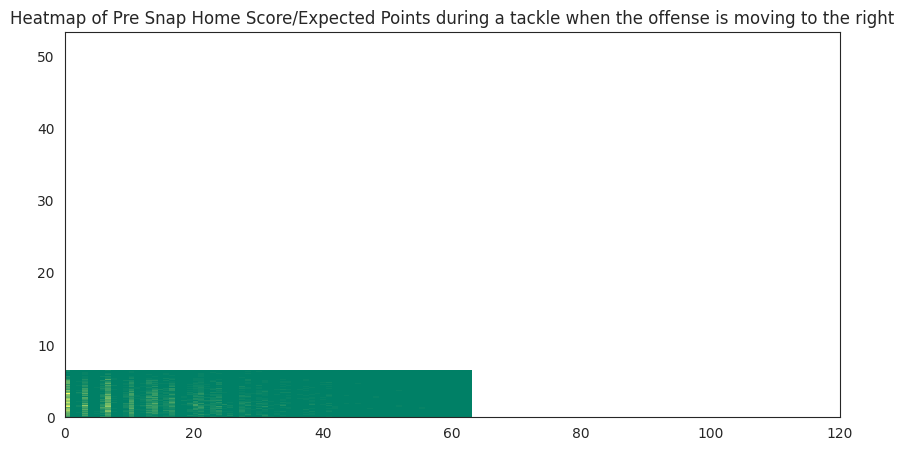

In [ ]:
#By Lennart Haupts https://www.kaggle.com/code/lennarthaupts/getting-a-feel-for-the-tracking-data

fig, ax = plt.subplots(figsize=(10,5))
plt.hist2d(right['pre_snap_home_score'][right['tackle'] == 1.0], right['expected_points'][right['tackle'] == 1.0],bins=70, cmap='summer')
plt.xlim(0 , 120)
plt.ylim(0,  53.3)
plt.title('Heatmap of Pre Snap Home Score/Expected Points during a tackle when the offense is moving to the right')
plt.show()

## Draft Session: 3h:8m

#Acknowledgements:

Yusufu Murtaza https://www.kaggle.com/code/yusufmurtaza01/s6e3-eda-training

Sanjay V https://www.kaggle.com/code/sanjayv007/nfl-big-data-bowl-beginner-s-complete-eda

Chinta https://www.kaggle.com/chinta/mlb-is-player-age-important

Lennart Haupts https://www.kaggle.com/code/lennarthaupts/getting-a-feel-for-the-tracking-data

Rob Mulla https://www.kaggle.com/code/robikscube/sign-language-recognition-eda-twitch-stream